# Phase 4: Portfolio Construction (กลยุทธ์จัดพอร์ต 4 รูปแบบ)
สร้างฟังก์ชันคำนวณน้ำหนักพอร์ต (Equal-Weight, Inverse-Volatility, Minimum-Variance, และ Maximum-Sharpe)
พร้อมกำหนดข้อจำกัด (Constraints): น้ำหนักรวม = 1, ห้าม Short, และถือหุ้นแต่ละตัวได้ไม่เกิน 20%

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from src.data import load_price_matrix
from src.risk import calculate_annualized_return, calculate_annualized_volatility, calculate_sharpe_ratio

# 1. โหลด Price Matrix ทั้งหมด
prices = load_price_matrix()

# 2. แยก Benchmark (TDEX.BK) ออกไป เหลือเฉพาะหุ้น 16 ตัวที่จะจัดเข้าพอร์ต
stock_prices = prices.drop(columns=["TDEX.BK"])
stock_returns = stock_prices.pct_change().dropna()

print(f"จำนวนหุ้นที่จะนำมาจัดพอร์ต: {stock_returns.shape[1]} ตัว")
print(f"จำนวนวันทำการทั้งหมด: {stock_returns.shape[0]} วัน")
stock_returns.head(3)

จำนวนหุ้นที่จะนำมาจัดพอร์ต: 16 ตัว
จำนวนวันทำการทั้งหมด: 2429 วัน


ticker,ADVANC.BK,AOT.BK,BBL.BK,BDMS.BK,BH.BK,BJC.BK,CPALL.BK,CPN.BK,DELTA.BK,KBANK.BK,KTB.BK,MINT.BK,PTT.BK,PTTEP.BK,SCC.BK,TTB.BK
date,,,,,,,,,,,,,,,,
2015-01-06,-0.008032,-0.003663,-0.002631,-0.011111,0.007220,-0.018319,-0.005882,0.000000,-0.028985,-0.027272,-0.031674,-0.039370,0.025397,0.000000,-0.017778,-0.014184
2015-01-07,0.024291,0.040441,0.010554,0.005618,0.000000,0.024973,0.023668,0.005618,0.104477,0.018691,0.042056,0.016394,0.034056,-0.004673,0.000000,0.021583
2015-01-08,-0.011857,0.021201,0.002611,0.039106,0.007168,0.012048,0.000000,0.011173,0.000000,0.045872,0.013453,0.040323,0.017964,0.032864,0.013575,0.028169


### Notes: กลยุทธ์ที่ 1 & 2 (Equal-Weight & Inverse-Volatility)

**1. Equal-Weight (EW) - ซื้อเท่ากันทุกตัว:**
- สูตร: $w_i = 1 / N$
- โค้ด: `weights = np.repeat(1.0 / n, n)`
  - **`np.repeat(a, repeats)` คืออะไร?**: เป็นฟังก์ชันของ NumPy ใช้ทำซ้ำ (repeat) ค่าหรือ array `a` ตามจำนวนครั้ง `repeats`
  - **การทำงานในที่นี้**: `1.0 / n` คือค่าน้ำหนักต่อตัว (เช่น มีหุ้น 16 ตัว จะได้ $1/16 = 0.0625$ หรือ $6.25\%$) และ `n = 16` คือจำนวนรอบที่ทำซ้ำ
  - **ผลลัพธ์**: ได้ 1D NumPy array ขนาด 16 ช่อง ที่มีค่า `0.0625` เท่ากันทั้งหมด: `array([0.0625, 0.0625, ..., 0.0625])`
  - **ทำไมไม่ใช้ list comprehension?**: การใช้ `np.repeat` เป็น C-level Vectorization ทำงานเร็วกว่า และได้ NumPy array พร้อมส่งต่อเข้า `pd.Series` หรือนำไปคูณ Matrix/Dot Product ทันที

---

**2. Inverse-Volatility (IV) - ให้น้ำหนักตามความนิ่ง (ผกผันกับความเสี่ยง):**
- สูตร: $w_i = \frac{1 / \sigma_i}{\sum_{j=1}^N (1 / \sigma_j)}$
- หุ้นที่ $\sigma$ ต่ำ (ผันผวนน้อย/นิ่ง) จะได้ค่า $1/\sigma$ สูง $\to$ **ได้น้ำหนักเงินเยอะ**
- หุ้นที่ $\sigma$ สูง (เหวี่ยงแรง/เสี่ยงสูง) จะได้ค่า $1/\sigma$ ต่ำ $\to$ **ได้น้ำหนักเงินน้อย**
- **ข้อดี**: กระจายความเสี่ยงดีกว่า EW เพราะไม่ทุ่มเงินใส่หุ้นเหวี่ยงแรงในสัดส่วนเท่ากับหุ้นนิ่ง

In [2]:
# จำลองดึงข้อมูลช่วง 3 ปีแรก (2015-2017) มาทดสอบการจัดพอร์ต
sample_returns = stock_returns.loc["2015-01-01":"2017-12-31"]

def get_equal_weights(returns: pd.DataFrame) -> pd.Series:
    """คำนวณน้ำหนัก Equal-Weight (1/N เท่ากันทุกตัว)"""
    n = returns.shape[1]
    weights = np.repeat(1.0 / n, n)
    return pd.Series(weights, index=returns.columns, name="Equal_Weight")

def get_inverse_vol_weights(returns: pd.DataFrame) -> pd.Series:
    """คำนวณน้ำหนัก Inverse-Volatility (ผกผันกับความผันผวนรายหุ้น)"""
    vols = returns.std() * np.sqrt(252)
    inv_vols = 1.0 / vols
    weights = inv_vols / inv_vols.sum()
    return pd.Series(weights, index=returns.columns, name="Inverse_Vol")

# ทดสอบรันและดูผลเปรียบเทียบ
ew = get_equal_weights(sample_returns)
iv = get_inverse_vol_weights(sample_returns)

df_compare = pd.DataFrame({
    "Equal_Weight (%)": ew * 100,
    "Inverse_Vol (%)": iv * 100
}).round(2)

df_compare.sort_values(by="Inverse_Vol (%)", ascending=False)

,Equal_Weight (%),Inverse_Vol (%)
ticker,,
BBL.BK,6.25,8.24
SCC.BK,6.25,7.98
BDMS.BK,6.25,7.91
KTB.BK,6.25,7.16
CPALL.BK,6.25,6.94
KBANK.BK,6.25,6.64
AOT.BK,6.25,6.61
CPN.BK,6.25,6.41
TTB.BK,6.25,5.96


### Deep-Dive: ทำความเข้าใจคณิตศาสตร์ & SciPy Optimization ในการจัดพอร์ต

#### 1. `returns.cov()` คำนวณมาจากสูตรอะไร?
- **Sample Covariance** ระหว่างหุ้น $X$ และ $Y$ ตลอด $T$ วันทำการ คำนวณจากสูตร:
  $$\text{Cov}(X, Y) = \sigma_{XY} = \frac{1}{T - 1} \sum_{t=1}^{T} (X_t - \bar{X})(Y_t - \bar{Y})$$
- เมื่อมีหุ้น $N$ ตัว (ในที่นี้คือ 16 ตัว) `returns.cov()` จะสร้าง **Covariance Matrix ($\mathbf{\Sigma}$)** ขนาด $16 \times 16$:
  - **แนวทแยงมุมหลัก (Diagonal)**: $\text{Cov}(X_i, X_i) = \text{Var}(X_i) = \sigma_i^2$ (ความแปรปรวนของหุ้นตัวเอง)
  - **นอกแนวทแยง (Off-diagonal)**: $\text{Cov}(X_i, X_j) = \sigma_{ij} = \rho_{ij} \sigma_i \sigma_j$ (การเคลื่อนไหวร่วมกันและ Correlation ระหว่างคู่หุ้น)
- **ทำไมต้องคูณ `* 252`?**: เพราะ `returns.cov()` ให้ผลลัพธ์เป็น Covariance รายวัน (Daily) จึงต้องคูณ 252 วันทำการเพื่อแปลงเป็น **Annualized Covariance Matrix** (เนื่องจาก $\text{Var}_{annual} = 252 \times \text{Var}_{daily}$)

---

#### 2. `weights @ cov_matrix @ weights` คืออะไร?
- เครื่องหมาย `@` ใน Python คือ **Matrix Multiplication** (`np.matmul` หรือ Dot Product)
- มาจากสูตร **Portfolio Variance** (ความแปรปรวนของพอร์ตรวม) ตามทฤษฎี Markowitz MPT:
  $$\sigma_p^2 = \mathbf{w}^T \mathbf{\Sigma} \mathbf{w} = \sum_{i=1}^N \sum_{j=1}^N w_i w_j \sigma_{ij}$$
- **มิติของเมทริกซ์ที่คูณกัน**:
  $$\underbrace{\mathbf{w}^T}_{[1 \times 16]} \times \underbrace{\mathbf{\Sigma}}_{[16 \times 16]} \times \underbrace{\mathbf{w}}_{[16 \times 1]} = \underbrace{\sigma_p^2}_{[1 \times 1]} \quad \text{(ได้ตัวเลขสเกลาร์ตัวเดียว คือ ความแปรปรวนของพอร์ต)}$$
- ตัวอย่างกรณี 2 หุ้นเพื่อความเข้าใจง่าย: $\sigma_p^2 = w_1^2 \sigma_1^2 + w_2^2 \sigma_2^2 + 2 w_1 w_2 \sigma_{12}$

---

#### 3. `constraints = {"type": "eq", "fun": lambda w: np.sum(w) - 1.0}` คืออะไร?
- ใน `scipy.optimize.minimize`, เงื่อนไขแบบสมการ (`type: eq`) นิยามตามหลักคณิตศาสตร์ว่า:
  $$g(\mathbf{w}) = 0$$
- เราต้องการให้เงินลงทุนรวมเป็น 100% พอดีเสมอ:
  $$\sum_{i=1}^N w_i = 1 \iff \sum_{i=1}^N w_i - 1 = 0$$
- ฟังก์ชัน `lambda w: np.sum(w) - 1.0` คือ $g(\mathbf{w})$ ที่ส่งให้ Optimizer ตรวจสอบว่าในทุกๆ สเต็ปของการปรับน้ำหนัก ผลบวกน้ำหนักลบ 1 ต้องมีค่าเท่ากับ 0 เสมอ

---

#### 4. `result = minimize(portfolio_variance, w0, method="SLSQP", bounds=bounds, constraints=constraints)` คืออะไร?
- นี่คือคำสั่งที่สั่งให้ SciPy เป็น "นักแก้สมการค้นหาน้ำหนักที่ดีที่สุด":
  - **`portfolio_variance` (Objective Function)**: ฟังก์ชันเป้าหมายที่ต้องการบีบให้มีค่าต่ำสุด (Minimize $\mathbf{w}^T \mathbf{\Sigma} \mathbf{w}$)
  - **`w0` (Initial Guess)**: จุดเริ่มต้นค้นหา เช่น ตั้งต้นด้วย Equal-Weight `[1/16, ..., 1/16]` เพื่อให้ Optimizer เริ่มขยับจุด
  - **`method="SLSQP"`**: ย่อมาจาก *Sequential Least Squares Programming* เป็นอัลกอริทึมมาตรฐานที่ออกแบบมาเพื่อแก้ Non-linear Optimization ที่มีทั้ง **Bounds** (ขอบเขต) และ **Constraints** (สมการข้อบังคับ)
  - **`bounds=bounds`**: กำหนดกรอบของหุ้นแต่ละตัว $0.0 \le w_i \le 0.20$ (ห้าม Short และไม่ถือเกิน 20% ต่อตัว)
  - **`constraints=constraints`**: บังคับให้ผลรวมน้ำหนักเท่ากับ 1.0 เสมอ
  - **`result.x`**: ผลลัพธ์ Array ของน้ำหนักพอร์ตที่ดีที่สุด (Optimal Weights $\mathbf{w}^*$) ที่ค้นพบ

In [3]:
def get_min_variance_weights(returns: pd.DataFrame, max_weight: float = 0.20) -> pd.Series:
    """คำนวณน้ำหนัก Minimum-Variance พอร์ตที่มีความผันผวนต่ำที่สุด"""
    n = returns.shape[1]
    cov_matrix = returns.cov().values * 252
    
    def portfolio_variance(weights):
        return weights @ cov_matrix @ weights
    
    constraints = {"type": "eq", "fun": lambda w: np.sum(w) - 1.0}
    bounds = tuple((0.0, max_weight) for _ in range(n))
    w0 = np.repeat(1.0 / n, n)
    
    result = minimize(portfolio_variance, w0, method="SLSQP", bounds=bounds, constraints=constraints)
    return pd.Series(result.x, index=returns.columns, name="Min_Variance")

def get_max_sharpe_weights(returns: pd.DataFrame, risk_free_rate: float = 0.025, max_weight: float = 0.20) -> pd.Series:
    """คำนวณน้ำหนัก Maximum-Sharpe (Tangency Portfolio) ที่ให้ผลตอบแทนเทียบความเสี่ยงสูงสุด"""
    n = returns.shape[1]
    mean_returns = returns.mean().values * 252
    cov_matrix = returns.cov().values * 252
    
    # minimize ค่าติดลบของ Sharpe Ratio (เทียบเท่า maximize Sharpe Ratio)
    def negative_sharpe(weights):
        p_ret = weights @ mean_returns
        p_vol = np.sqrt(weights @ cov_matrix @ weights)
        if p_vol == 0:
            return 0.0
        return -(p_ret - risk_free_rate) / p_vol
    
    constraints = {"type": "eq", "fun": lambda w: np.sum(w) - 1.0}
    bounds = tuple((0.0, max_weight) for _ in range(n))
    w0 = np.repeat(1.0 / n, n)
    
    result = minimize(negative_sharpe, w0, method="SLSQP", bounds=bounds, constraints=constraints)
    return pd.Series(result.x, index=returns.columns, name="Max_Sharpe")

# ทดสอบคำนวณน้ำหนักทั้ง 4 กลยุทธ์บน sample_returns (2015-2017)
min_var = get_min_variance_weights(sample_returns)
max_shp = get_max_sharpe_weights(sample_returns)

df_all_weights = pd.DataFrame({
    "Equal_Weight (%)": ew * 100,
    "Inverse_Vol (%)": iv * 100,
    "Min_Variance (%)": min_var * 100,
    "Max_Sharpe (%)": max_shp * 100
}).round(2)

print("=== เปรียบเทียบน้ำหนักพอร์ตทั้ง 4 กลยุทธ์ (Sample: 2015-2017) ===")
df_all_weights

=== เปรียบเทียบน้ำหนักพอร์ตทั้ง 4 กลยุทธ์ (Sample: 2015-2017) ===


,Equal_Weight (%),Inverse_Vol (%),Min_Variance (%),Max_Sharpe (%)
ticker,,,,
ADVANC.BK,6.25,5.66,7.31,0.00
AOT.BK,6.25,6.61,6.42,20.00
BBL.BK,6.25,8.24,18.62,0.00
BDMS.BK,6.25,7.91,20.00,0.46
BH.BK,6.25,5.42,1.98,5.83
BJC.BK,6.25,4.86,5.83,17.86
CPALL.BK,6.25,6.94,12.78,20.00
CPN.BK,6.25,6.41,0.00,20.00
DELTA.BK,6.25,4.68,5.01,1.75


### Notes: ทำความเข้าใจผลลัพธ์ (Optimization Insights & Comparison)

#### 1. โค้ดบรรทัดไหนคือกำหนดเพดาน 20%?
- บรรทัดนี้ในฟังก์ชัน `get_min_variance_weights` และ `get_max_sharpe_weights`:
  ```python
  bounds = tuple((0.0, max_weight) for _ in range(n))
  ```
  - พารามิเตอร์ตั้งต้น: `max_weight: float = 0.20`
  - `0.0`: ขอบล่าง (Lower bound) คือห้ามติดลบ หรือ **Long-only** (ห้าม Short-selling)
  - `0.20`: ขอบบน (Upper bound) คือเพดานเงินลงทุนสูงสุดต่อหุ้น 1 ตัว ห้ามเกิน 20%
  - `for _ in range(n)`: กำหนดกรอบ `(0.0, 0.20)` ให้กับหุ้นทั้ง $n$ ตัว (16 ตัว) ในรูป tuple

---

#### 2. `scipy.optimize.minimize` กับ `Gradient Descent` เหมือนหรือต่างกันอย่างไร?
- **จุดที่เหมือนกัน**: ทั้งคู่คือ **Iterative Optimization** ที่ต้องการหาจุดต่ำสุดของ Loss / Objective function โดยใช้ทิศทางความชัน (Gradient $\nabla f$) เพื่อขยับตัวแปร $\mathbf{w}$
- **จุดที่ต่างกัน (ทำไมต้อง SLSQP?)**:
  - Vanilla Gradient Descent ในงาน Deep Learning ทั่วไปเป็นแบบ **Unconstrained** ถ้าเอามาใช้จัดพอร์ต ค่าน้ำหนักที่ก้าวไปจะทำให้ผลรวมเงิน $\sum w_i \ne 1.0$ หรือน้ำหนักติดลบได้ง่ายๆ
  - **`method="SLSQP"`** ย่อมาจาก *Sequential Least Squares Programming* ถูกสร้างขึ้นมาเพื่อแก้ปัญหา **Constrained Optimization** โดยเฉพาะ:
    - ใช้หลักการ **Lagrange Multipliers + KKT Conditions** และประมาณการแบบ Quadratic Programming (คล้าย 2nd-order Newton's method)
    - ไม่ต้องจูน Learning Rate ($\alpha$) และสามารถวิ่งค้นหาคำตอบโดย "เกาะอยู่บนเส้นขอบเขตของเงื่อนไข" ได้อย่างแม่นยำ

---

#### 3. สรุป 3 Findings สำคัญจากตารางผลลัพธ์ (Sample 2015–2017):
1. **การทำงานของ Bounds 20% (Cap เพดานได้จริง)**:
   - **Min-Var**: ทุ่มเงินให้ `BDMS` ชนเพดาน **20.00%** พอดีเป๊ะ (ถ้าไม่มี Bounds มันอาจเทไป 40-50%)
   - **Max-Sharpe**: ทุ่มเงินให้ผู้ชนะ 3 ตัวชนเพดาน **20.00%** เต็มเหยียดทั้ง 3 ตัว คือ `AOT`, `CPALL`, `CPN` (รวม 3 ตัวนี้ = 60% ของพอร์ต)
2. **Min-Var เหนือกว่า Inverse-Vol เพราะดู Correlation & Covariance**:
   - Inverse-Vol ดูแค่ความผันผวนรายตัว ($\sigma_i$) จึงเฉลี่ยเงินให้ทุกคน (ไม่มีหุ้นตัวไหนได้ 0%)
   - แต่ Min-Var ดูการเคลื่อนไหวร่วมกันด้วย: สังเกตหุ้นแบงก์ (`BBL`, `KBANK`, `KTB`) ที่มี Correlation สูงมาก (~0.8-0.9) Min-Var จึงเลือกทุ่มให้ `BBL` ตัวเดียว (18.62%) แล้วตัด `KBANK` และ `KTB` เป็น **0.00%** ทิ้งทันที เพราะการถือหุ้นที่ขยับไปทางเดียวกันไม่ได้ช่วยลดความแปรปรวนรวม
3. **ปัญหาคลาสสิกของ Max-Sharpe ("Error Maximizer")**:
   - Max-Sharpe เทเงินเกือบทั้งหมด (78%+) ให้กลุ่มค้าปลีก/ท่องเที่ยว (`AOT`, `CPALL`, `CPN`, `BJC`) และให้แบงก์เป็น 0%
   - นี่คือภาพสะท้อนของการ **Overfit กับข้อมูลอดีต (Hindsight Bias)** ตัวไหนขึ้นดีในอดีตจะถูกทุ่มเงินใส่จนล้น ซึ่งถ้าอนาคตกลุ่มนี้สะดุด พอร์ตจะเสียหายหนัก ต่างจาก Min-Var หรือ Equal-Weight ที่ทนทานกว่า

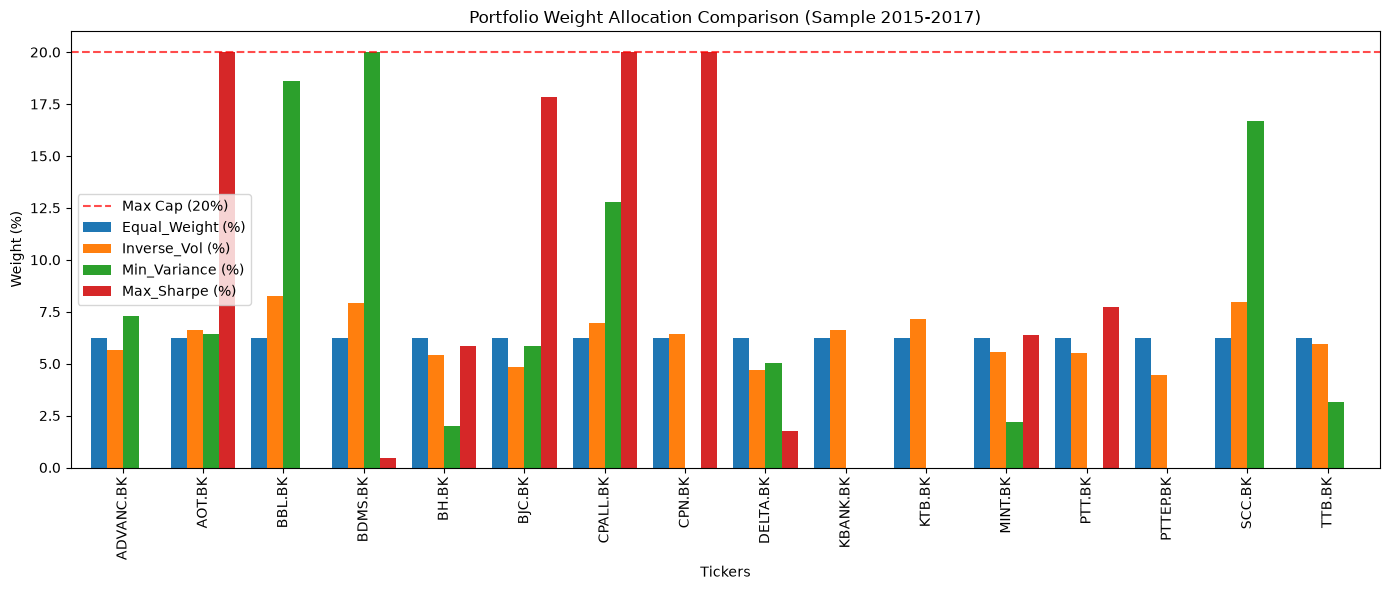

In [4]:
# พล็อต Bar Chart เปรียบเทียบน้ำหนัก 4 กลยุทธ์
ax = df_all_weights.plot(
    kind="bar", 
    figsize=(14, 6), 
    width=0.8,
    title="Portfolio Weight Allocation Comparison (Sample 2015-2017)"
)
ax.set_ylabel("Weight (%)")
ax.set_xlabel("Tickers")
ax.axhline(20, color="red", linestyle="--", alpha=0.7, label="Max Cap (20%)")
ax.legend()
plt.tight_layout()
plt.show()

### Phase 4 Checkpoint: สรุปความเข้าใจเชิงลึก (Interview Readiness)

**Q1: ทำไมในทางปฏิบัติ (Real-world Quant) กลยุทธ์ Minimum-Variance ถึงมักเสถียรกว่า Maximum-Sharpe?**
- **คำตอบ & หัวใจสำคัญ**: 
  - **Mean Estimation Error vs Covariance Stability**: การพยายามทำนายผลตอบแทนในอนาคต ($\mu$) จากข้อมูลในอดีตมี Noise สูงมาก ทำให้ Max-Sharpe กลายเป็น *"Error Maximizer"* มักจะ Overfit ทุ่มเงินให้หุ้นที่บังเอิญขึ้นแรงในอดีตเพียงไม่กี่ตัว
  - ตรงกันข้าม **Covariance Matrix ($\mathbf{\Sigma}$)** มีความเสถียร (Stationary) ข้ามเวลามากกว่ามาก และ Min-Var วิเคราะห์จาก Correlation/การเคลื่อนไหวร่วมกัน ทำให้คัดเลือกและกระจายความเสี่ยงออกนอกกลุ่ม (Cross-sector Diversification) ได้ทนทานกว่าเมื่อนำไปใช้จริง Out-of-Sample

---

**Q2: การกำหนดข้อจำกัด `max_weight = 0.20` (เพดานไม่เกิน 20% ต่อหุ้น) ช่วยแก้ปัญหาอะไรในการบริหารกองทุนจริง?**
- **คำตอบ & หัวใจสำคัญ**:
  - **แก้ปัญหา Concentration Risk**: หากไม่ใส่เพดาน Optimizer มักจะเจอปัญหาทางคณิตศาสตร์ที่เรียกว่า *"Corner Solution"* คือทุ่มเงิน 40–60% ไปที่หุ้นตัวเดียว ทำให้พอร์ตเสี่ยงเกินไปหากหุ้นตัวนั้นสะดุด (Idiosyncratic Risk)
  - **สอดคล้องกับเกณฑ์กำกับดูแล (Regulatory Compliance)**: ในการบริหารกองทุนรวมจริง ก.ล.ต. (SEC) มีกฎหมายคุมสัดส่วน Single-Entity Limit (ห้ามถือหุ้นบริษัทหรือกลุ่มธุรกิจเดียวกันเกิน 15–20% ของ NAV) เพื่อคุ้มครองนักลงทุน